<a href="https://colab.research.google.com/github/sebastianvettel1212/Scikit-Learn-Cookbook/blob/main/scikit_learn_Cookbook_Chapter_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 10 — Teknik *Clustering* (*Clustering Techniques*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 10 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku ditandai dengan komentar `# Catatan:` di dalam sel. (Teks pembuka notebook resmi Bab 10 di repositori buku tertulis "text classification and multiclass classification", yang keliru: bab ini membahas *clustering*.)

---

## Daftar Isi
0. Persiapan
1. *K-Means Clustering*
2. *Hierarchical Clustering*
3. *Density-Based Clustering* dengan DBSCAN
4. Metrik Evaluasi *Clustering* (*Cluster Evaluation Metrics*)
5. Memilih Algoritma *Clustering* yang Tepat
6. Teknik *Clustering* Lanjutan (*Spectral Clustering* dan *Gaussian Mixture Models*)
7. Latihan Praktik
8. Ringkasan Bab

---

## Pengantar
Bab 5–9 membahas **pembelajaran terawasi** (*supervised*): ada label yang harus ditebak. **Clustering** adalah **pembelajaran tak terawasi** (*unsupervised*): tidak ada label, dan tujuannya menemukan **kelompok alami** pada data berdasarkan kemiripan (jarak atau kepadatan). Aplikasinya antara lain segmentasi pelanggan, pengelompokan dokumen, dan kompresi data. Karena tidak ada "jawaban benar" yang pasti, pemilihan algoritma dan evaluasinya lebih menyerupai seni daripada sains (catatan buku), tetapi tetap ada alat yang membantu.

## 0. Persiapan

In [1]:
!pip install numpy pandas scipy scikit-learn matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('Versi scikit-learn:', sklearn.__version__)

Versi scikit-learn: 1.6.1


---
## 1. *K-Means Clustering*

### Teori
***K-Means*** adalah algoritma berbasis **centroid**: membagi data ke $K$ kelompok dengan **$K$ ditentukan di awal**. Tujuannya meminimalkan ***inertia*** (*within-cluster sum of squares*, WCSS):
$$J=\sum_{k=1}^{K}\ \sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^{2}$$
dengan $\mu_k$ centroid (rata-rata) kelompok $k$. Algoritma Lloyd mengulangi dua langkah hingga konvergen:

1. **Inisialisasi:** pilih $K$ centroid awal (bawaan `init='k-means++'`, yang menyebar centroid awal agar saling berjauhan sehingga hasilnya lebih stabil daripada acak murni).
2. **Penugasan (*assignment*):** setiap titik masuk ke centroid terdekat (jarak Euclidean).
3. **Pembaruan (*update*):** centroid dihitung ulang sebagai rata-rata anggota kelompoknya.

Kelebihan: cepat dan skalabel. Keterbatasan: harus menentukan $K$; peka terhadap inisialisasi (hanya mencapai optimum **lokal**, sehingga dijalankan beberapa kali lewat `n_init`); peka terhadap skala fitur (jarak Euclidean, jadi **standardisasi** diperlukan); dan cenderung membentuk kelompok **cembung, bulat, berukuran serupa**, yang bisa menjadi kelemahan terbesarnya (catatan buku).

Inertia selalu turun saat $K$ naik (pada $K=n$ nilainya 0), sehingga tidak bisa dipakai langsung untuk memilih $K$. Metode ***elbow*** mencari titik tempat penurunan inertia mulai melandai ("siku").

### Getting ready
Data buatan dengan `make_blobs()`: 300 titik, 4 pusat, simpangan baku 0,60, lalu distandardisasi (*z-score*).

In [3]:
# Load the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# Create the dataset
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
X = StandardScaler().fit_transform(X)
print('Bentuk data:', X.shape)

Bentuk data: (300, 2)


### How to do it...
Lihat dulu data hasil pembangkitan; `StandardScaler()` sudah dipakai agar klaster mudah divisualisasikan.

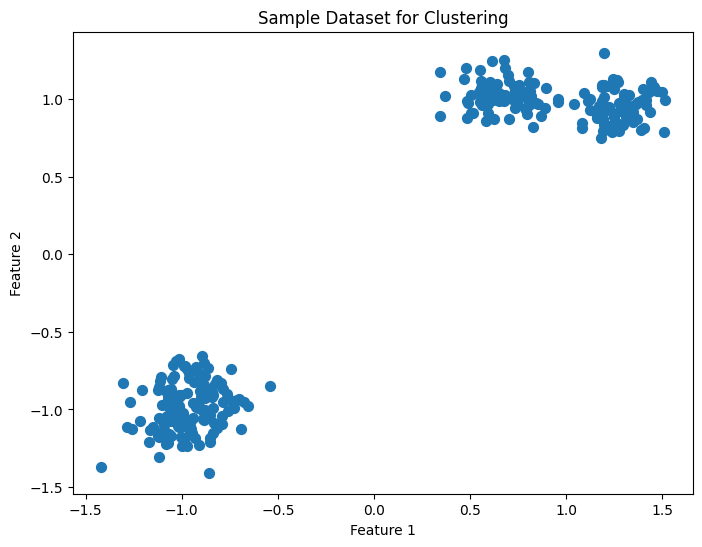

In [4]:
# Visualize the raw data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Sample Dataset for Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Interpretasi:** data tampak seperti **tiga gugus**: dua gugus berdampingan di kanan-atas dan satu gugus lebih besar di kiri-bawah, padahal data dibangkitkan dengan **4 pusat**. Gugus kiri-bawah ternyata terdiri dari dua pusat yang saling menumpuk. Ini peringatan sejak awal bahwa "jumlah kelompok sebenarnya" pada data nyata sering tidak tegas, bahkan ketika kita mengetahui cara data dibangkitkan.

Sekarang terapkan *K-Means* dengan `n_clusters=4` (satu-satunya argumen wajib).

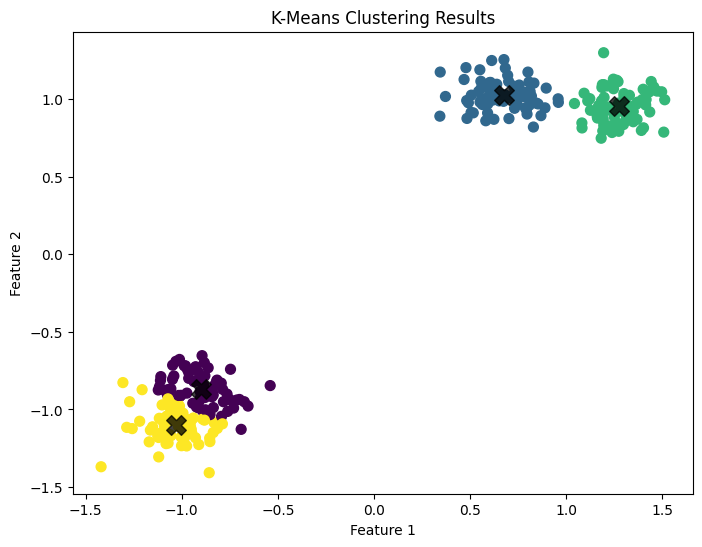

Ukuran tiap klaster: [71 77 73 79] | inertia = 7.3 | iterasi sampai konvergen: 4


In [5]:
# Load the libraries
from sklearn.cluster import KMeans

# Apply K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Plot the clustered data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.75, marker='X')
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
print('Ukuran tiap klaster:', np.bincount(y_kmeans), '| inertia =', round(kmeans.inertia_, 2), '| iterasi sampai konvergen:', kmeans.n_iter_)

**Interpretasi:** *K-Means* dengan `n_clusters=4` membentuk empat klaster berukuran seimbang (71, 77, 73, 79 titik) dan konvergen hanya dalam 4 iterasi dengan *inertia* 7,3. Dua klaster di kanan-atas terpisah rapi, tetapi gugus kiri-bawah **dibelah dua secara agak arbitrer** karena kedua pusat aslinya saling menumpuk; batas belahannya tidak bisa dipulihkan dengan tepat oleh algoritma apa pun.

### How it works...
*K-Means* bekerja lewat penyempurnaan iteratif: inisialisasi centroid → penugasan titik ke centroid terdekat → pembaruan centroid, hingga penugasan tidak berubah atau mencapai iterasi maksimum. Metode *elbow* membantu memilih $K$:

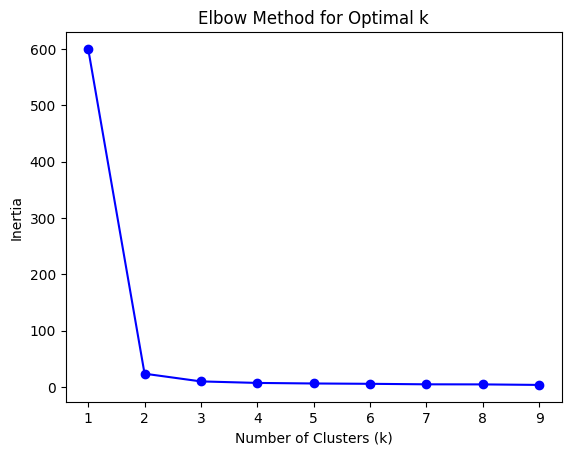

{1: 600.0, 2: 23.7, 3: 10.0, 4: 7.3, 5: 6.3, 6: 5.7, 7: 4.8, 8: 4.7, 9: 3.8}


In [6]:
# Calculate and plot clustering inertia
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(k_values, inertia, 'bo-')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()
print({k: round(v, 1) for k, v in zip(k_values, inertia)})

**Interpretasi:** *inertia* turun tajam dari 600 (K=1) ke 23,7 (K=2) dan 10,0 (K=3), lalu melandai pelan: 7,3 (K=4), 6,3, 5,7, dan seterusnya. "Siku" jatuh sekitar **K=2 sampai K=4**, sehingga metode ini tidak memberi satu jawaban tegas, itulah keterbatasan *elbow*. Sebagai catatan, nilai 600 pada K=1 bukan kebetulan: pada data terstandardisasi 2 fitur, jumlah kuadrat jarak ke rata-rata adalah $n\times p=300\times 2$.

### Tambahan: *silhouette* untuk memilih $K$ dan kestabilan inisialisasi
Kurva *elbow* bersifat subjektif. Skor *silhouette* (dibahas rinci pada subbab 4) memberi angka yang bisa dibandingkan. Kita juga memeriksa apakah inisialisasi acak (`init="random"`, satu kali jalan) memberi hasil yang berbeda dari `k-means++`.

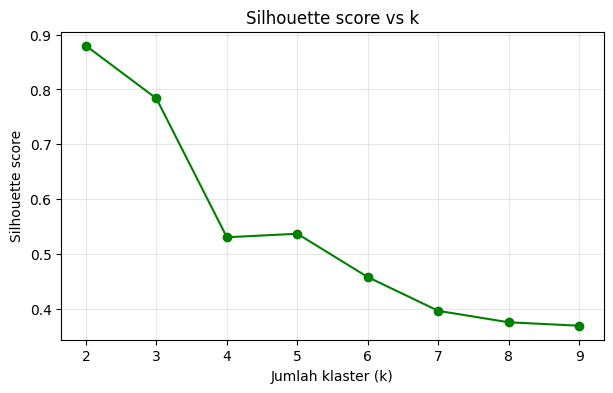

k terbaik menurut silhouette: 2 | skor = 0.88


,inertia min,inertia maks,jumlah seed dg hasil buruk (> min*1.05)
random,7.29,20.41,16.0
k-means++,7.29,9.30,6.0


In [7]:
# Tambahan (tidak ada di kode buku)
from sklearn.metrics import silhouette_score

ks = range(2, 10)
sil = [silhouette_score(X, KMeans(n_clusters=k, random_state=2024, n_init=10).fit_predict(X)) for k in ks]
plt.figure(figsize=(7, 4))
plt.plot(list(ks), sil, 'go-'); plt.xlabel('Jumlah klaster (k)'); plt.ylabel('Silhouette score')
plt.title('Silhouette score vs k'); plt.grid(alpha=0.3); plt.show()
print('k terbaik menurut silhouette:', list(ks)[int(np.argmax(sil))], '| skor =', round(max(sil), 3))

# Kestabilan inisialisasi: 20 seed berbeda, satu kali jalan (n_init=1) per seed
res = {}
for init in ['random', 'k-means++']:
    inert = [KMeans(n_clusters=4, init=init, n_init=1, random_state=s).fit(X).inertia_ for s in range(20)]
    res[init] = {'inertia min': min(inert), 'inertia maks': max(inert), 'jumlah seed dg hasil buruk (> min*1.05)': int(sum(i > min(inert) * 1.05 for i in inert))}
pd.DataFrame(res).T.round(2)

**Interpretasi:**
- ***Silhouette*** memuncak pada **K=2** (0,88), bukan K=4. Ini masuk akal: ada dua gugus besar yang sangat berjauhan, sehingga pembagian menjadi dua terlihat paling "bersih", meski pembangkit data memakai 4 pusat. *Elbow* dan *silhouette* menjawab pertanyaan yang sedikit berbeda, dan keduanya tidak sepakat dengan struktur "sebenarnya".
- **Kestabilan inisialisasi** (20 *seed*, satu kali jalan): inisialisasi `random` menghasilkan *inertia* terbaik 7,29 tetapi terburuk **20,41**, dan 16 dari 20 *seed* berada > 5% di atas yang terbaik. `k-means++` jauh lebih stabil (terburuk 9,30; 6 dari 20 *seed* kurang baik). Keduanya tetap bisa terjebak optimum lokal, sebab itu `n_init` > 1 dipakai (nilai bawaan versi baru `n_init='auto'` hanya 1 jalan untuk `k-means++`).

### Key Ideas
- *K-Means* meminimalkan **inertia** lewat siklus penugasan–pembaruan centroid; cepat, tetapi butuh $K$ dan menganggap klaster bulat.
- Pilih $K$ dengan *elbow* **dan** *silhouette*; standardisasi fitur sebelum memakai jarak Euclidean.
- Gunakan `k-means++` dan `n_init` > 1 agar tidak terjebak optimum lokal.

---
## 2. *Hierarchical Clustering*

### Teori
***Hierarchical clustering*** membangun klaster **bersarang** (pohon) sehingga tidak harus menentukan jumlah klaster di awal. Ada dua pendekatan: ***agglomerative*** (dari bawah ke atas; setiap titik awalnya satu klaster lalu digabung) dan ***divisive*** (dari atas ke bawah). scikit-learn hanya mendukung *agglomerative*.

Pada tiap langkah, dua klaster **terdekat** digabung. Definisi "jarak antarklaster" ditentukan oleh ***linkage***:

| Linkage | Jarak antar klaster $A$ dan $B$ | Kecenderungan |
|---|---|---|
| **Ward** (bawaan) | pertambahan total variansi dalam-klaster akibat penggabungan | klaster kompak berukuran seimbang |
| **Complete** | $\max_{a\in A,b\in B}d(a,b)$ | klaster kompak |
| **Average** | rata-rata $d(a,b)$ semua pasangan | kompromi |
| **Single** | $\min_{a\in A,b\in B}d(a,b)$ | bisa mengikuti bentuk memanjang, tetapi rentan "efek rantai" (*chaining*) |

Hasilnya divisualisasikan sebagai ***dendrogram***: sumbu-y menunjukkan jarak saat penggabungan terjadi. **Memotong dendrogram** pada tinggi tertentu menghasilkan sejumlah klaster; lompatan besar pada tinggi gabung menandakan jumlah klaster alami. Kelemahan: kompleksitas waktu kuadratik atau lebih (kurang skalabel) dan keputusan penggabungan tidak dapat dibatalkan.

### Getting ready
Data yang sama (blobs terstandardisasi), dengan `AgglomerativeClustering` dari scikit-learn dan `linkage`/`dendrogram` dari SciPy.

In [8]:
# Load the libraries
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Reuse the dataset from the earlier section
# Dataset already loaded and scaled as X
print('Data:', X.shape)

Data: (300, 2)


### How to do it...
Kita dapat menentukan jumlah klaster, atau menentukan ambang jarak sebagai titik potong; salah satunya saja.

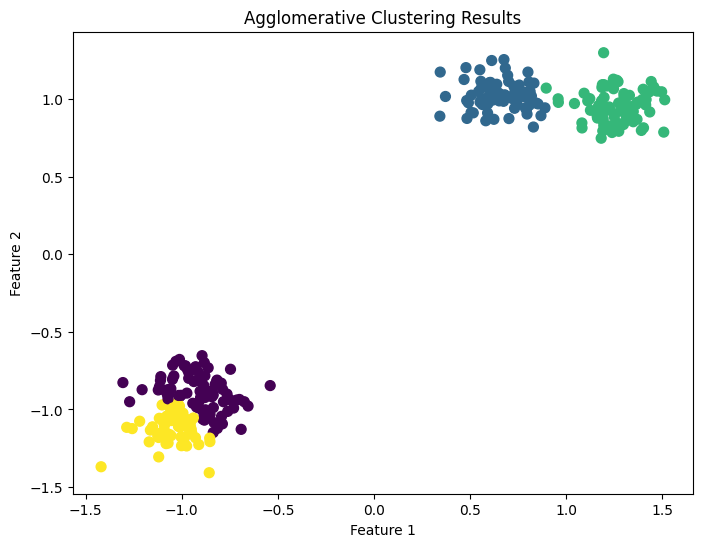

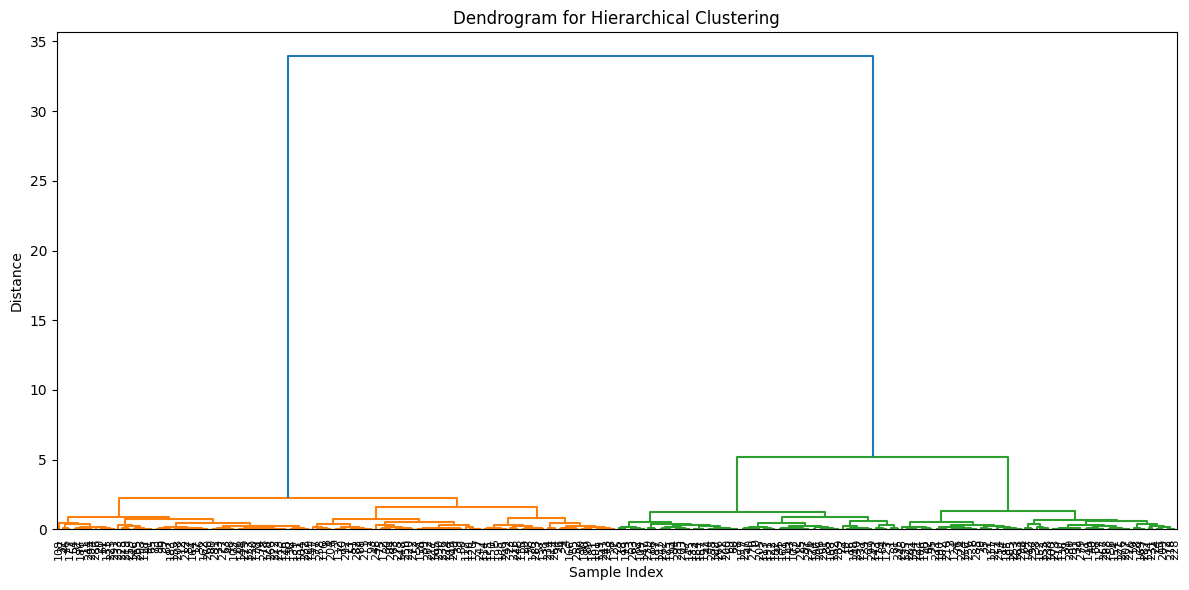

Ukuran tiap klaster: [82 74 76 68]
5 jarak penggabungan terakhir (Ward): [ 1.28  1.58  2.25  5.21 33.95]


In [9]:
# Apply agglomerative clustering
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

# Plot the clustered data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Generate the dendrogram using SciPy
linked = linkage(X, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
print('Ukuran tiap klaster:', np.bincount(y_agg))
print('5 jarak penggabungan terakhir (Ward):', linked[-5:, 2].round(2))

**Interpretasi:** *agglomerative* (Ward, 4 klaster) menghasilkan klaster berukuran 82, 74, 76, 68. Pada dendrogram, jarak penggabungan terakhir berturut-turut 1,28; 1,58; 2,25; **5,21**; dan **33,95**. Lompatan terbesar (dari 5,21 ke 33,95) menandakan bahwa penggabungan dua gugus besar terakhir memaksa pemisahan yang sangat berjauhan, konsisten dengan struktur dua gugus besar; lompatan sedang dari 2,25 ke 5,21 menunjukkan pembagian menjadi 3–4 klaster masih wajar. Jadi memotong dendrogram memberi pilihan jumlah klaster yang transparan, tidak harus ditentukan di muka.

### How it works...
*Agglomerative clustering* bekerja dari bawah ke atas: tiap titik adalah klaster, dua klaster terdekat digabung (menurut kriteria *linkage*) sampai tersisa satu klaster atau kriteria berhenti terpenuhi. Dendrogram memperlihatkan seluruh riwayat penggabungan.

### There's more...: membandingkan *linkage*

In [10]:
# Tambahan (tidak ada di kode buku): perbandingan linkage pada data berlabel (ARI = kecocokan dengan label sebenarnya)
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score

Xb, yb = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
Xb = StandardScaler().fit_transform(Xb)
Xm, ym = make_moons(n_samples=300, noise=0.05, random_state=2024)

rows = []
for link in ['ward', 'complete', 'average', 'single']:
    rows.append({'Linkage': link,
                 'ARI pada blobs (k=4)': adjusted_rand_score(yb, AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(Xb)),
                 'ARI pada moons (k=2)': adjusted_rand_score(ym, AgglomerativeClustering(n_clusters=2, linkage=link).fit_predict(Xm))})
pd.DataFrame(rows).set_index('Linkage').round(3)

,ARI pada blobs (k=4),ARI pada moons (k=2)
Linkage,,
ward,0.793,0.209
complete,0.747,0.425
average,0.696,0.488
single,0.494,1.000


**Interpretasi:** pilihan *linkage* mengubah hasil secara drastis dan hasilnya bergantung pada bentuk data. Pada **blobs** (klaster kompak), *Ward* terbaik (ARI 0,793) dan *single* terburuk (0,494). Pada **moons** (bulan sabit), kebalikannya: *single* sempurna (**1,000**), sedangkan *Ward* hanya **0,209**. *Single linkage* mengikuti rantai titik berdekatan sehingga cocok untuk bentuk memanjang, tetapi pada data berisik rentan efek rantai; *Ward* menyukai klaster bulat berukuran seimbang.

### Key Ideas
- *Agglomerative clustering* menggabungkan klaster terdekat secara bertahap dan menghasilkan **dendrogram** yang memperlihatkan seluruh hierarki.
- Pilihan ***linkage*** menentukan bentuk klaster: *Ward* untuk klaster kompak, *single* untuk bentuk memanjang (rawan efek rantai).
- Kurang skalabel dibanding *K-Means* karena kompleksitas waktu yang lebih tinggi.

---
## 3. *Density-Based Clustering* dengan DBSCAN

### Teori
***DBSCAN*** (*Density-Based Spatial Clustering of Applications with Noise*) mendefinisikan klaster sebagai **wilayah padat** yang dipisahkan wilayah jarang. Kelebihannya dibanding *K-Means*: **tidak perlu menentukan jumlah klaster**, dapat menemukan klaster **berbentuk sembarang**, dan **menandai *noise*** (label `-1`) alih-alih memaksa semua titik masuk klaster. Dua parameter utama:

- **`eps` ($\varepsilon$):** radius lingkungan di sekitar titik, $N_\varepsilon(p)=\{q:\lVert p-q\rVert\le\varepsilon\}$.
- **`min_samples`:** jumlah minimum titik (termasuk titik itu sendiri) dalam radius `eps` agar wilayah dianggap padat.

Setiap titik masuk salah satu dari tiga kategori:

| Kategori | Definisi |
|---|---|
| ***Core point*** | $\lvert N_\varepsilon(p)\rvert\ge$ `min_samples` |
| ***Border point*** | bukan *core*, tetapi berada dalam radius `eps` dari suatu *core point* |
| ***Noise point*** | bukan keduanya (label `-1`) |

Klaster dibentuk dengan menghubungkan *core point* yang saling berdekatan beserta *border point*-nya (*density-connected*). Memilih `eps`: gunakan **grafik *k-distance*** (jarak ke tetangga ke-$k$ untuk tiap titik, diurutkan) dan cari titik "siku" tempat kurva menanjak tajam.

Keterbatasan: peka terhadap `eps` dan `min_samples`, dan kesulitan bila kepadatan antar klaster sangat berbeda atau pada dimensi tinggi.

### Getting ready
Data `make_moons()` (dua bulan sabit) dengan *noise* 0,1, bentuk non-cembung yang membuat *K-Means* kesulitan.

In [11]:
# Load the libraries
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# Create a new one with noise
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
print('Bentuk data:', X.shape)

Bentuk data: (300, 2)


### How to do it...
Kita menjalankan DBSCAN dengan `eps=0.2` dan `min_samples=5`.

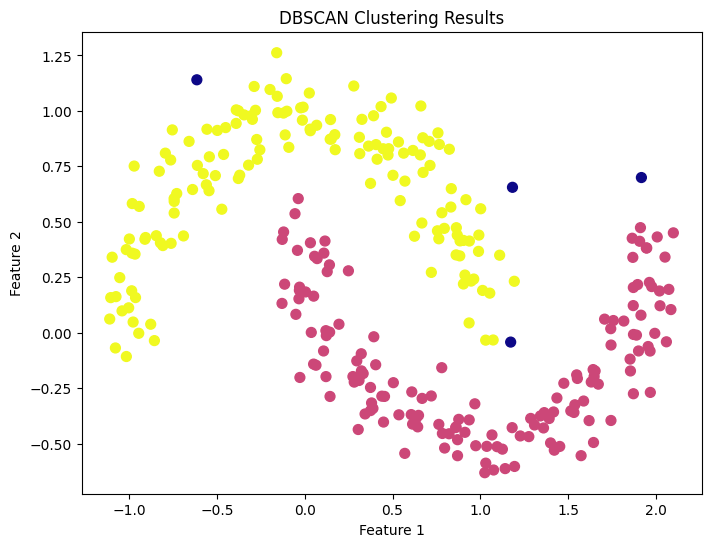

Label klaster (-1 = noise): {-1: 4, 0: 150, 1: 146}
Jumlah core point: 290


In [12]:
# Apply DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X)

# Plot the DBSCAN results
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_db, cmap='plasma', s=50)
plt.title("DBSCAN Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
labels_found, counts = np.unique(y_db, return_counts=True)
print('Label klaster (-1 = noise):', dict(zip(labels_found.tolist(), counts.tolist())))
print('Jumlah core point:', len(dbscan.core_sample_indices_))

**Interpretasi:** DBSCAN dengan `eps=0.2` dan `min_samples=5` menemukan **dua klaster** (150 dan 146 titik) serta **4 titik *noise*** (label −1), tepat sesuai bentuk dua bulan sabit; 290 dari 300 titik adalah *core point*. Tanpa diberi tahu jumlah klaster, DBSCAN memulihkan strukturnya dengan sempurna kecuali pada beberapa titik di tepi yang dianggap *noise*.

### How it works...
DBSCAN dimulai dari titik yang belum dikunjungi, memeriksa lingkungannya, lalu memperluas klaster secara rekursif lewat titik yang terhubung kepadatan. Ia baik dalam menemukan klaster non-bulat dan memisahkan *noise*.

### There's more...: grafik *k-distance* untuk memilih `eps`

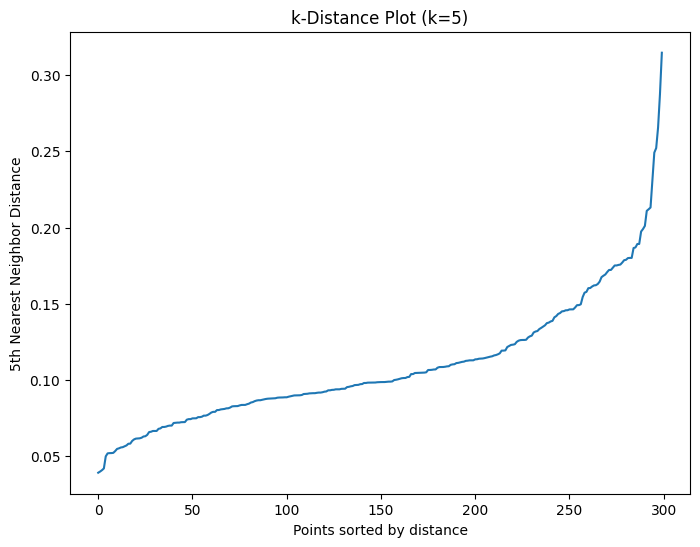

Jarak tetangga ke-5 -> persentil 50/90/95/99: [0.099 0.169 0.187 0.252]


In [13]:
# Load libraries
from sklearn.neighbors import NearestNeighbors

# Generate Nearest Neighbors
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, 4])

# Plot k-distance
plt.figure(figsize=(8, 6))
plt.plot(distances)
plt.title("k-Distance Plot (k=5)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()
print('Jarak tetangga ke-5 -> persentil 50/90/95/99:', np.percentile(distances, [50, 90, 95, 99]).round(3))

**Interpretasi:** jarak ke tetangga ke-5 bernilai ≈ 0,10 pada median, 0,17 pada persentil ke-90, 0,19 pada persentil ke-95, dan melonjak ke 0,25 pada persentil ke-99. "Siku" kurva (titik tempat jarak mulai menanjak tajam) berada di sekitar **0,17–0,25**, dan nilai `eps=0.2` yang dipakai berada tepat di daerah itu: cukup besar agar sebagian besar titik padat terhubung, tetapi cukup kecil untuk menyisakan titik pencilan sebagai *noise*.

### Tambahan: sensitivitas terhadap `eps`, dan *K-Means* pada data bulan sabit

In [14]:
# Tambahan (tidak ada di kode buku)
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=300, noise=0.1, random_state=2024)

rows = []
for eps in [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Xm)
    rows.append({'eps': eps, 'Jumlah klaster': len(set(lab)) - (1 if -1 in lab else 0), 'Titik noise': int((lab == -1).sum()),
                 'ARI vs label sebenarnya': adjusted_rand_score(ym, lab)})
display(pd.DataFrame(rows).set_index('eps').round(3))

km_lab = KMeans(n_clusters=2, random_state=2024, n_init=10).fit_predict(Xm)
print(f'K-Means (k=2) pada moons: ARI = {adjusted_rand_score(ym, km_lab):.3f}')
print(f'DBSCAN (eps=0.2)       : ARI = {adjusted_rand_score(ym, DBSCAN(eps=0.2, min_samples=5).fit_predict(Xm)):.3f}')

,Jumlah klaster,Titik noise,ARI vs label sebenarnya
eps,,,
0.05,4,279,0.011
0.10,18,62,0.088
0.20,2,4,0.960
0.30,1,0,0.000
0.50,1,0,0.000
0.80,1,0,0.000


K-Means (k=2) pada moons: ARI = 0.241
DBSCAN (eps=0.2)       : ARI = 0.960


**Interpretasi:** DBSCAN **sangat peka terhadap `eps`**: `eps=0.05` → 4 klaster dan 279 titik *noise* (hampir semuanya dibuang; ARI 0,011); `eps=0.1` → 18 klaster kecil (ARI 0,088); **`eps=0.2` → 2 klaster, 4 *noise* (ARI 0,960)**; `eps ≥ 0.3` → seluruh titik menyatu menjadi **satu klaster** (ARI 0). Rentang `eps` yang benar-benar bekerja sempit, sehingga grafik *k-distance* sangat membantu. Sebagai pembanding, *K-Means* (k=2) hanya ARI **0,241** pada data yang sama, karena membelah data dengan garis lurus dan bukan mengikuti bentuk bulan sabit.

### Key Ideas
- DBSCAN menemukan klaster berdasarkan **kepadatan**: tanpa menentukan jumlah klaster, mendukung bentuk sembarang, dan menandai *noise* (`-1`).
- Parameter `eps` dan `min_samples` sangat menentukan; gunakan grafik ***k-distance*** sebagai panduan.
- *K-Means* gagal pada klaster non-cembung seperti bulan sabit; DBSCAN tidak.

---
## 4. Metrik Evaluasi *Clustering* (*Cluster Evaluation Metrics*)

### Teori
Karena tidak ada label, evaluasi *clustering* memakai metrik **internal** (hanya memakai data dan hasil klaster) dan **eksternal** (membandingkan dengan label sebenarnya bila ada):

| Metrik | Jenis | Rumus / ide | Interpretasi |
|---|---|---|---|
| **Silhouette** | internal | $s(i)=\dfrac{b(i)-a(i)}{\max\{a(i),b(i)\}}$, $a$ = rata-rata jarak ke anggota klaster sendiri, $b$ = rata-rata jarak ke klaster terdekat lain | −1 sampai 1; **makin tinggi makin baik** |
| **Davies-Bouldin** | internal | rata-rata kemiripan tiap klaster dengan klaster paling mirip: $\dfrac1K\sum_i\max_{j\ne i}\dfrac{s_i+s_j}{d_{ij}}$ | $\ge 0$; **makin rendah makin baik**; menghukum klaster tumpang-tindih |
| **Calinski-Harabasz** | internal | rasio dispersi antar-klaster terhadap dalam-klaster: $\dfrac{SS_B/(K-1)}{SS_W/(n-K)}$ | **makin tinggi makin baik** (*variance ratio criterion*) |
| **Adjusted Rand Index (ARI)** | eksternal | menghitung pasangan sampel yang dikelompokkan sama/berbeda dibanding label sebenarnya, **dikoreksi kebetulan** | −1 sampai 1; 1 = sempurna, ≈ 0 = acak |

Peringatan penting: metrik internal seperti *silhouette* **cenderung menyukai klaster cembung dan padat**, sehingga bisa memberi skor lebih rendah pada hasil yang sebenarnya benar tetapi berbentuk non-cembung (lihat sel Tambahan).

### Getting ready
Data blobs berlabel (label sebenarnya `y_true` disimpan kali ini) dan model *K-Means*.

In [15]:
# Load the libraries
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate a labeled dataset for evaluation
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)

# Fit KMeans for use with evaluation metrics
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

### How to do it...
Metrik dihitung langsung dari data masukan dan hasil klaster.

In [16]:
# Calculate the silhouette score
sil_score = silhouette_score(X, y_kmeans)
print(f"Silhouette Score: {sil_score:.3f}")

# Calculate the Davies-Bouldin index
db_index = davies_bouldin_score(X, y_kmeans)
print(f"Davies-Bouldin Index: {db_index:.3f}")

# (Optional) Calculate adjusted Rand index if ground truth is known
ari = adjusted_rand_score(y_true, y_kmeans)
print(f"Adjusted Rand Index: {ari:.3f}")

Silhouette Score: 0.534
Davies-Bouldin Index: 0.702
Adjusted Rand Index: 0.814


**Interpretasi:** *silhouette* 0,534 (menengah: klaster cukup terpisah tetapi ada tumpang-tindih), *Davies-Bouldin* 0,702 (makin rendah makin baik), dan **ARI 0,814** (kecocokan tinggi dengan 4 pusat sebenarnya, tetapi belum sempurna karena dua pusat yang saling menumpuk tidak dapat dipisahkan tepat). Ketiga angka konsisten menunjukkan hasil yang layak namun tidak sempurna.

### How it works...
- **Silhouette:** seberapa mirip sebuah titik dengan klasternya dibanding klaster lain (−1 buruk, 1 padat dan terpisah baik).
- **Davies-Bouldin:** rata-rata rasio kemiripan tiap klaster dengan klaster terdekatnya; **makin rendah makin baik**.
- **ARI:** membandingkan hasil klaster dengan label sebenarnya, terkoreksi kebetulan.

### There's more...
Metrik tambahan: **Calinski-Harabasz** (*variance ratio criterion*), yang juga memakai dispersi antar-klaster dan dalam-klaster.

In [17]:
# Tambahan (tidak ada di kode buku): ketiga metrik internal + ARI untuk berbagai k, dan jebakan metrik internal pada moons
from sklearn.metrics import calinski_harabasz_score
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

rows = []
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=2024, n_init=10).fit_predict(X)
    rows.append({'k': k, 'Silhouette (tinggi=baik)': silhouette_score(X, lab),
                 'Davies-Bouldin (rendah=baik)': davies_bouldin_score(X, lab),
                 'Calinski-Harabasz (tinggi=baik)': calinski_harabasz_score(X, lab),
                 'ARI': adjusted_rand_score(y_true, lab)})
display(pd.DataFrame(rows).set_index('k').round(3))

# Jebakan: pada moons, hasil yang benar (DBSCAN) justru kalah menurut silhouette
Xm, ym = make_moons(n_samples=300, noise=0.05, random_state=2024)
km_m = KMeans(n_clusters=2, random_state=2024, n_init=10).fit_predict(Xm)
db_m = DBSCAN(eps=0.2, min_samples=5).fit_predict(Xm)
pd.DataFrame({'Silhouette': [silhouette_score(Xm, km_m), silhouette_score(Xm, db_m)],
              'ARI (terhadap label sebenarnya)': [adjusted_rand_score(ym, km_m), adjusted_rand_score(ym, db_m)]},
             index=['K-Means (k=2)', 'DBSCAN (eps=0.2)']).round(3)

,Silhouette (tinggi=baik),Davies-Bouldin (rendah=baik),Calinski-Harabasz (tinggi=baik),ARI
k,,,,
2,0.887,0.169,8523.616,0.497
3,0.768,0.390,8819.986,0.697
4,0.534,0.702,8670.779,0.814
5,0.520,0.754,7409.599,0.761
6,0.450,0.875,6732.693,0.663
7,0.389,0.983,6530.483,0.556


,Silhouette,ARI (terhadap label sebenarnya)
K-Means (k=2),0.487,0.254
DBSCAN (eps=0.2),0.329,1.000


**Interpretasi:**
- **Metrik internal tidak sepakat satu sama lain, dan tidak sepakat dengan label sebenarnya.** *Silhouette* dan *Davies-Bouldin* memilih **K=2** (0,887 dan 0,169); *Calinski-Harabasz* memilih **K=3** (8.820); sedangkan ARI (memakai label sebenarnya) memuncak di **K=4** (0,814). Metrik internal menyukai klaster yang terpisah jelas, sehingga dua pusat yang menumpuk "dilebur".
- **Jebakan metrik internal:** pada *moons*, *K-Means* mendapat *silhouette* lebih tinggi (0,487) daripada DBSCAN (0,329), padahal DBSCAN **sempurna** (ARI 1,000) dan *K-Means* hanya 0,254. *Silhouette* mengukur kekompakan/jarak, bukan kebenaran bentuk, sehingga memihak klaster cembung.

### Key Ideas
- **Silhouette**, **Davies-Bouldin**, dan **Calinski-Harabasz** menilai kualitas klaster tanpa label; **ARI** membandingkannya dengan label sebenarnya jika tersedia.
- Metrik internal menyukai klaster cembung; jangan memakainya sebagai satu-satunya penentu pada data berbentuk kompleks.
- Gunakan beberapa metrik bersama visualisasi dan pengetahuan domain.

---
## 5. Memilih Algoritma *Clustering* yang Tepat

### Teori
Tidak ada algoritma yang terbaik untuk semua data. Perbandingan menurut buku:

| Faktor | *K-Means* | *Hierarchical* | *DBSCAN* | *Spectral* | *GMM* |
|---|---|---|---|---|---|
| **Bentuk klaster** | cembung/bulat | tergantung *linkage* | sembarang | sembarang (non-cembung) | elips |
| **Menangani *noise*** | tidak | tidak | **ya** (label −1) | tidak | tidak (tetapi ada probabilitas) |
| **Skalabilitas** | **baik** | kurang | cukup | kurang | cukup |
| **Parameter utama** | $K$, inisialisasi | *linkage*, ambang/$K$ | `eps`, `min_samples` | $K$, ukuran *affinity* | jumlah komponen |
| **Jumlah klaster diketahui?** | perlu | tidak perlu (potong dendrogram) | tidak perlu | perlu | perlu |

Pada **dimensi tinggi**, jarak kehilangan makna (*curse of dimensionality*, Bab 3), sehingga biasanya diperlukan **reduksi dimensi** (mis. PCA) sebelum *clustering*. Saran buku: **plot data mentah terlebih dahulu** untuk melihat struktur yang dapat memandu pilihan.

### Getting ready
Tiga dataset dengan struktur berbeda: *blobs* (bulat), *moons* (bulan sabit), dan *circles* (lingkaran bersarang), semuanya distandardisasi.

In [18]:
# Load the libraries
from sklearn.datasets import make_moons, make_blobs, make_circles
from sklearn.preprocessing import StandardScaler

# Create and scale different datasets
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
X_moons, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_circles, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)

X_blobs = StandardScaler().fit_transform(X_blobs)
X_moons = StandardScaler().fit_transform(X_moons)
X_circles = StandardScaler().fit_transform(X_circles)

### How to do it...
Setiap struktur data cocok dengan algoritma tertentu; pertama kita lihat bentuknya.

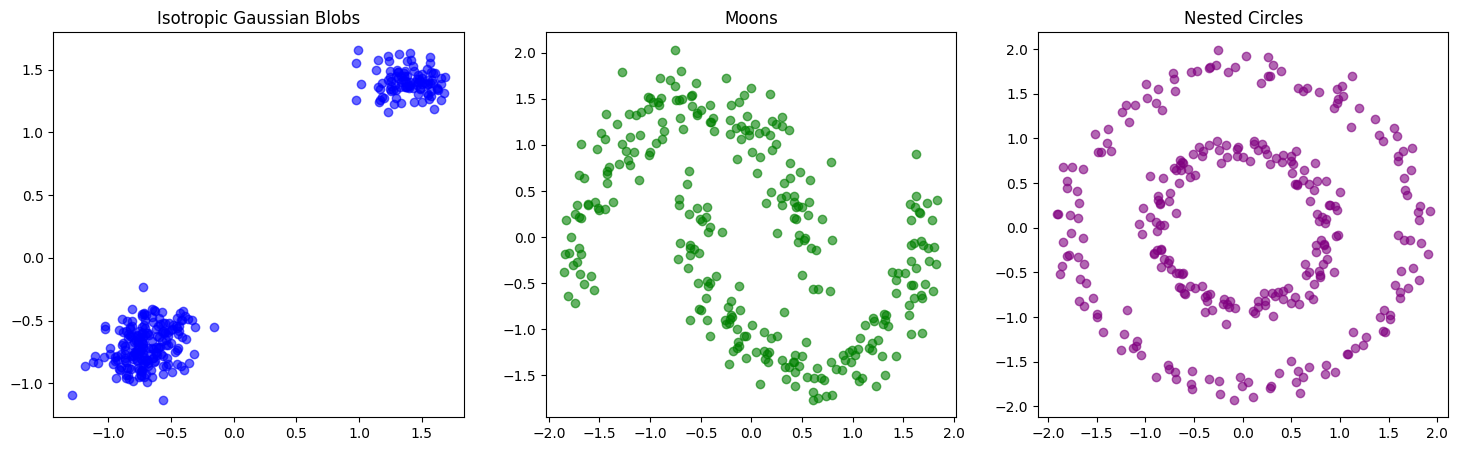

In [19]:
# Visualize the datasets
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c='blue', alpha=0.6)
axs[0].set_title("Isotropic Gaussian Blobs")
axs[1].scatter(X_moons[:, 0], X_moons[:, 1], c='green', alpha=0.6)
axs[1].set_title("Moons")
axs[2].scatter(X_circles[:, 0], X_circles[:, 1], c='purple', alpha=0.6)
axs[2].set_title("Nested Circles")
plt.show()

**Interpretasi:** tiga dataset memperlihatkan tiga struktur berbeda: *blobs* (gugus bulat), *moons* (dua bulan sabit yang saling mengait), dan *circles* (satu lingkaran di dalam lingkaran lain). *Moons* dan *circles* tidak dapat dipisahkan oleh garis lurus atau pembagian berbasis centroid, sedangkan *blobs* cocok untuk algoritma berbasis centroid.

### Tambahan: lima algoritma pada tiga dataset
Untuk membuktikan bahwa "tidak ada satu algoritma untuk semua", kelima algoritma bab ini dijalankan pada ketiga dataset (label sebenarnya dipakai hanya untuk menghitung ARI).

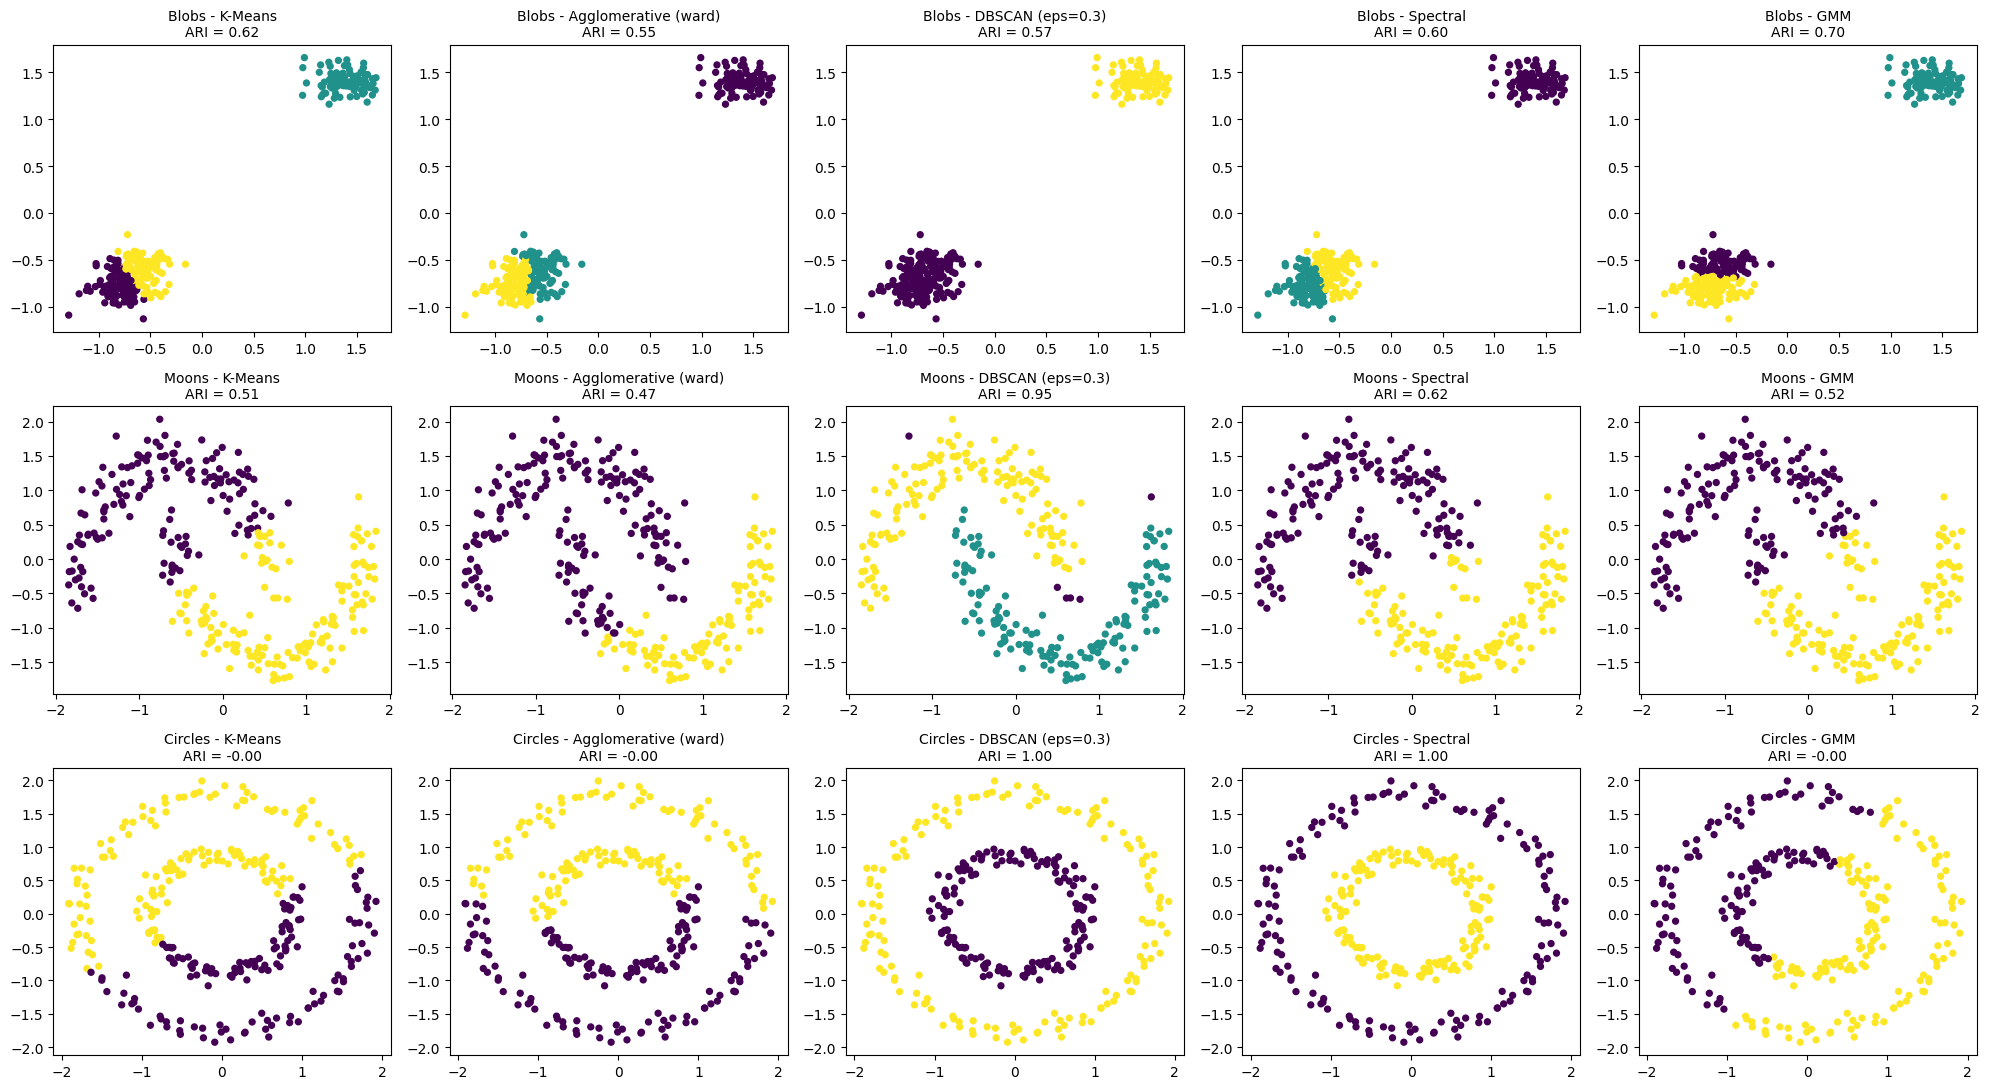

,K-Means,Agglomerative (ward),DBSCAN (eps=0.3),Spectral,GMM
Blobs,0.623,0.552,0.570,0.599,0.698
Moons,0.507,0.470,0.948,0.618,0.517
Circles,-0.003,-0.003,1.000,1.000,-0.003


In [20]:
# Tambahan (tidak ada di kode buku)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture

sets = {
    'Blobs': (make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024), 3),
    'Moons': (make_moons(n_samples=300, noise=0.1, random_state=2024), 2),
    'Circles': (make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024), 2),
}
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
ari_table = {}
for r, (dname, ((Xd, yd), k)) in enumerate(sets.items()):
    Xd = StandardScaler().fit_transform(Xd)
    algos = {
        'K-Means': KMeans(n_clusters=k, random_state=2024, n_init=10),
        'Agglomerative (ward)': AgglomerativeClustering(n_clusters=k),
        'DBSCAN (eps=0.3)': DBSCAN(eps=0.3, min_samples=5),
        'Spectral': SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=2024),
        'GMM': GaussianMixture(n_components=k, random_state=2024),
    }
    for c, (aname, algo) in enumerate(algos.items()):
        lab = algo.fit_predict(Xd)
        ari = adjusted_rand_score(yd, lab)
        ari_table.setdefault(dname, {})[aname] = ari
        axes[r, c].scatter(Xd[:, 0], Xd[:, 1], c=lab, cmap='viridis', s=18)
        axes[r, c].set_title(f'{dname} - {aname}\nARI = {ari:.2f}', fontsize=10)
plt.tight_layout(); plt.show()
pd.DataFrame(ari_table).T.round(3)

**Interpretasi:** (ARI; 1 = sempurna, ≈ 0 = acak)
- **Circles:** *K-Means*, *Agglomerative* (Ward), dan *GMM* semuanya **≈ 0** (setara tebakan acak); hanya **DBSCAN** dan ***Spectral*** yang sempurna (1,000), karena keduanya mengikuti keterhubungan/kepadatan, bukan jarak ke pusat.
- **Moons:** DBSCAN terbaik (**0,948**), diikuti *Spectral* 0,618; *K-Means*, *Agglomerative*, dan *GMM* ≈ 0,47–0,52.
- **Blobs:** semua algoritma hanya **0,55–0,70** (terbaik *GMM* 0,698). Ini bukan kegagalan algoritma: pada gambar, dua dari tiga pusat menumpuk sehingga batasnya memang tidak terdefinisi tegas.
- **Pelajaran:** tidak ada algoritma yang menang di semua dataset; pemenang berganti sesuai bentuk data. Perhatikan juga bahwa *Spectral* yang sempurna pada *circles* hanya 0,618 pada *moons* ber-*noise* 0,1, jadi sensitif pada pengaturan graf.

### Key Ideas
- Pilih algoritma berdasarkan **bentuk klaster, adanya *noise*, skalabilitas, sensitivitas parameter, dan dimensi data**.
- *K-Means/GMM* cocok untuk klaster bulat/elips; *DBSCAN/Spectral* untuk bentuk non-cembung; *Hierarchical* bila hierarki berguna dan data tidak terlalu besar.
- **Visualisasikan data mentah dahulu**; pada dimensi tinggi lakukan reduksi dimensi.

---
## 6. Teknik *Clustering* Lanjutan (*Advanced Clustering Techniques*)

### Teori
**Spectral clustering** memakai teori graf: (1) membangun **graf kemiripan** (*affinity*) antar titik, mis. dengan `affinity='nearest_neighbors'` atau kernel RBF; (2) membentuk **matriks Laplacian** graf; (3) mengambil beberapa **vektor eigen** terkecilnya sebagai representasi berdimensi rendah; (4) menjalankan ***K-Means*** pada representasi tersebut. Karena klaster didefinisikan lewat **keterhubungan graf** (bukan jarak ke centroid), metode ini efektif untuk bentuk non-cembung.

***Gaussian Mixture Models (GMM)*** adalah klaster **lunak** (*soft clustering*): data diasumsikan dihasilkan dari campuran $K$ distribusi Gaussian,
$$p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal{N}(x\mid\mu_k,\Sigma_k)$$
Parameter ($\pi_k,\mu_k,\Sigma_k$) dicari dengan algoritma ***Expectation-Maximization (EM)***: langkah **E** menghitung probabilitas tiap titik berasal dari tiap komponen (*responsibility*), langkah **M** memperbarui parameter berdasarkan probabilitas itu; diulang hingga likelihood konvergen. Setiap titik mendapat **probabilitas keanggotaan** (`predict_proba`), dan matriks kovarians memungkinkan klaster **berbentuk elips** dan tumpang-tindih. Jumlah komponen dapat dipilih dengan ***BIC***/***AIC*** (makin rendah makin baik). Karena berbasis probabilitas, GMM juga dapat dipakai untuk deteksi anomali (Bab 11).

### Getting ready
Dataset *moons* dengan *noise* 0,05 (bentuk non-cembung), distandardisasi.

In [21]:
# Load the libraries
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture
# Create datasets with complex structure
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X, _ = make_moons(n_samples=300, noise=0.05, random_state=2024)
X = StandardScaler().fit_transform(X)

### How to do it...
Kedua model dilatih dengan cara yang mirip model sebelumnya.

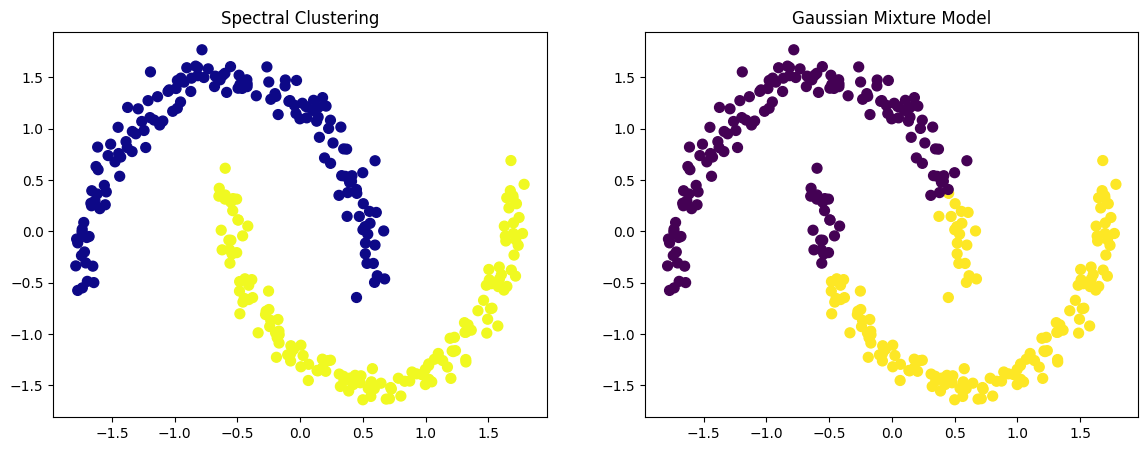

ARI Spectral = 1.000 | ARI GMM = 0.526


In [22]:
# Apply Spectral Clustering
spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)
y_spectral = spectral.fit_predict(X)

# Apply Gaussian Mixture Model
gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X)

# Visualize both clustering results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_spectral, cmap='plasma', s=50)
ax1.set_title("Spectral Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_gmm, cmap='viridis', s=50)
ax2.set_title("Gaussian Mixture Model")

plt.show()
_, ym_adv = make_moons(n_samples=300, noise=0.05, random_state=2024)
print(f'ARI Spectral = {adjusted_rand_score(ym_adv, y_spectral):.3f} | ARI GMM = {adjusted_rand_score(ym_adv, y_gmm):.3f}')

**Interpretasi:** pada *moons* ber-*noise* kecil (0,05), ***Spectral clustering*** memulihkan kedua bulan sabit dengan sempurna (ARI **1,000**), sedangkan ***GMM*** hanya **0,526**: GMM mengasumsikan setiap klaster berbentuk elips Gaussian, sehingga membelah data dengan batas "elips" yang memotong kedua bulan sabit.

### How it works...
**Spectral clustering:** membangun graf kemiripan, membentuk matriks yang menyatakan hubungan antar titik, memetakannya ke ruang berdimensi lebih rendah, lalu menjalankan *K-Means* di sana; efektif untuk klaster non-cembung.

**GMM:** metode *soft clustering* berbasis campuran distribusi Gaussian; tiap titik mendapat probabilitas keanggotaan, dan algoritma EM memaksimalkan likelihood.

### There's more...: probabilitas keanggotaan dan pemilihan jumlah komponen dengan BIC

In [23]:
# Tambahan (tidak ada di kode buku): predict_proba dan BIC pada data blobs 4 pusat
Xg, yg = make_blobs(n_samples=300, centers=4, cluster_std=0.9, random_state=2024)   # std lebih besar -> klaster saling mendekat
Xg = StandardScaler().fit_transform(Xg)

bics = {k: GaussianMixture(n_components=k, random_state=2024, n_init=5).fit(Xg).bic(Xg) for k in range(1, 9)}
print('BIC per jumlah komponen:', {k: round(v, 1) for k, v in bics.items()})
print('Jumlah komponen terbaik menurut BIC:', min(bics, key=bics.get))

gmm4 = GaussianMixture(n_components=4, random_state=2024, n_init=5).fit(Xg)
proba = gmm4.predict_proba(Xg)
max_p = proba.max(axis=1)
print(f'Titik dengan keyakinan maksimum < 0,9 (area tumpang-tindih): {(max_p < 0.9).sum()} dari {len(Xg)}')
print('Contoh 3 titik paling tidak pasti (probabilitas tiap komponen):')
print(np.round(proba[np.argsort(max_p)[:3]], 3))

BIC per jumlah komponen: {1: np.float64(1079.9), 2: np.float64(307.4), 3: np.float64(317.2), 4: np.float64(347.1), 5: np.float64(371.6), 6: np.float64(400.4), 7: np.float64(426.2), 8: np.float64(451.0)}
Jumlah komponen terbaik menurut BIC: 2
Titik dengan keyakinan maksimum < 0,9 (area tumpang-tindih): 90 dari 300
Contoh 3 titik paling tidak pasti (probabilitas tiap komponen):
[[0.52  0.    0.    0.48 ]
 [0.543 0.    0.    0.457]
 [0.    0.554 0.446 0.   ]]


**Interpretasi:** pada data 4 pusat dengan sebaran lebih besar (std 0,9), **BIC terendah pada 2 komponen** (307,4), diikuti 3 komponen (317,2), sementara 4 komponen (347,1) lebih buruk; BIC menghukum kompleksitas dan memilih penjelasan paling hemat, sehingga pusat yang saling menumpuk digabungkan. Dengan 4 komponen, GMM memberi **probabilitas keanggotaan** per titik: **90 dari 300 titik** memiliki keyakinan maksimum < 0,9. Contoh titik paling tidak pasti terbagi hampir 50:50 (mis. 0,52 vs 0,48) antara dua komponen yang berdekatan. Informasi "seberapa yakin" ini tidak dimiliki *K-Means*, yang hanya memberi satu label tegas.

### Key Ideas
- ***Spectral clustering*** memakai graf kemiripan dan vektor eigen; kuat untuk klaster non-cembung.
- ***GMM*** adalah klaster lunak berbasis campuran Gaussian (EM): memberi probabilitas keanggotaan dan menangani klaster elips/tumpang-tindih, tetapi mengasumsikan bentuk Gaussian.
- Reduksi dimensi (PCA, t-SNE) sebelum *clustering* lanjutan sering meningkatkan kinerja dan interpretabilitas.

---
## 7. Latihan Praktik (*Practical Exercises with Clustering Models*)

Berikut solusi ketiga latihan dari berkas *Exercise Solutions* repositori resmi buku, dilengkapi interpretasi.

### Latihan 1: *K-Means* pada Dataset Iris
Menerapkan *K-Means* pada Iris dan mengevaluasinya dengan beberapa metrik.

Silhouette Score: 0.553
Adjusted Rand Index: 0.730


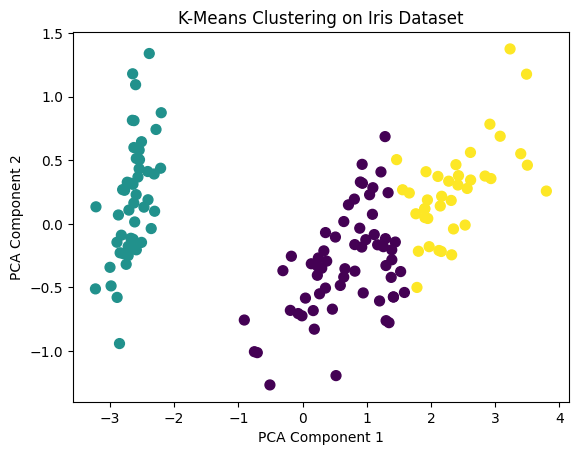

Klaster      0   1   2
Spesies               
setosa       0  50   0
versicolor  48   0   2
virginica   14   0  36


In [24]:
# Load libraries
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt

# Load the Dataset
iris = load_iris()
X = iris.data
y_true = iris.target

# Create and Train the KMeans Model
kmeans = KMeans(n_clusters=3, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Evaluate the Clustering
sil_score = silhouette_score(X, y_kmeans)
ari = adjusted_rand_score(y_true, y_kmeans)

print(f"Silhouette Score: {sil_score:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")

# Visualize the Cluster Assignments (PCA Projection)
from sklearn.decomposition import PCA

X_pca = PCA(n_components=2).fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, cmap='viridis', s=50)
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

# Tambahan: tabel silang klaster vs spesies sebenarnya
print(pd.crosstab(pd.Series(y_true, name='Spesies'), pd.Series(y_kmeans, name='Klaster')).rename(index=dict(enumerate(iris.target_names))))

**Interpretasi:** *silhouette* 0,553 dan **ARI 0,730**. Tabel silang menunjukkan *setosa* terpisah **sempurna** (50 di klaster 1), sedangkan *versicolor* (48) dan *virginica* (36) mendominasi klaster 0 dan 2, dengan 14 *virginica* dan 2 *versicolor* masuk klaster "yang salah" (16 dari 150 bunga). Pola kesalahannya sama dengan klasifikasi terawasi pada bab-bab sebelumnya: dua spesies ini bertumpang-tindih, meski kali ini model tidak pernah melihat label.

### Latihan 2: DBSCAN vs *K-Means* pada Data *Moons*
Memperlihatkan DBSCAN mengungguli *K-Means* pada bentuk non-cembung.

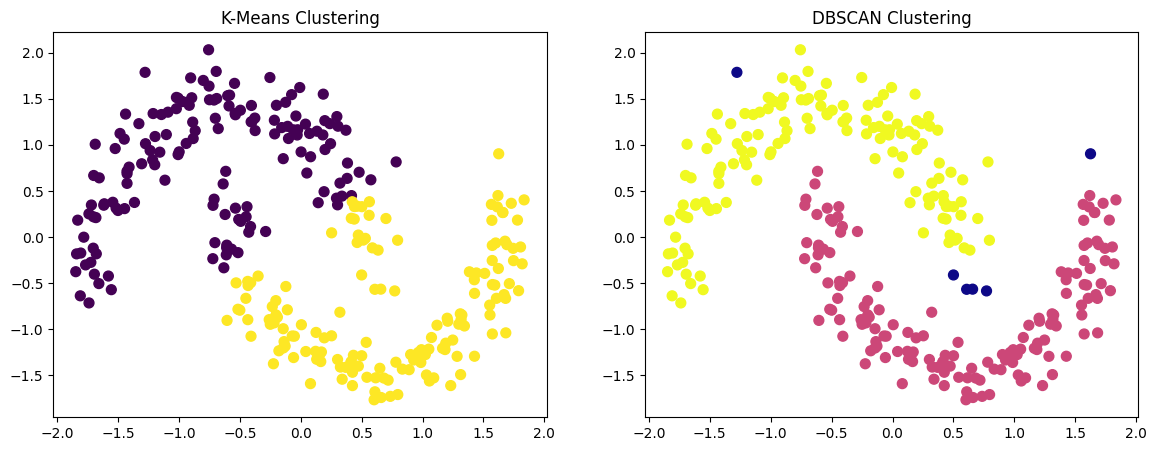

ARI K-Means: 0.507 | ARI DBSCAN: 0.948 | titik noise DBSCAN: 6


In [25]:
# Load libraries
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt

# Create and Scale the Dataset
X, y_moons = make_moons(n_samples=300, noise=0.1, random_state=2024)
X = StandardScaler().fit_transform(X)

# Apply KMeans and DBSCAN
kmeans = KMeans(n_clusters=2, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
y_dbscan = dbscan.fit_predict(X)

# Visualize the Clustering Results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis', s=50)
ax1.set_title("K-Means Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_dbscan, cmap='plasma', s=50)
ax2.set_title("DBSCAN Clustering")

plt.show()
print(f"ARI K-Means: {adjusted_rand_score(y_moons, y_kmeans):.3f} | ARI DBSCAN: {adjusted_rand_score(y_moons, y_dbscan):.3f} | titik noise DBSCAN: {(y_dbscan == -1).sum()}")

**Interpretasi:** pada *moons* terstandardisasi, DBSCAN (`eps=0.3`) mencapai ARI **0,948** dengan 6 titik *noise*, sedangkan *K-Means* hanya **0,507**. Gambar memperlihatkan *K-Means* membelah data dengan garis lurus yang memotong kedua bulan sabit, sedangkan DBSCAN mengikuti bentuknya. Catatan: `eps=0.3` bekerja di sini karena data distandardisasi (skala berubah), tidak sama dengan `eps=0.3` pada data mentah (lihat tabel sensitivitas `eps` di subbab 3).

### Latihan 3: Klaster Data Berdimensi Tinggi dengan PCA + GMM
Menggabungkan reduksi dimensi dengan klaster probabilistik pada dataset Wine (13 fitur).

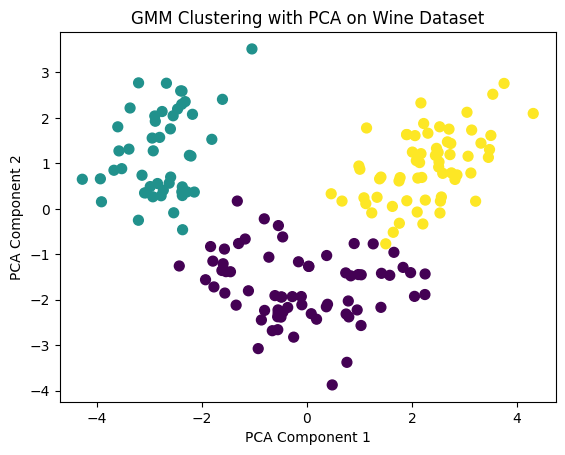

Variansi dijelaskan 2 komponen PCA: [0.362 0.192] | total = 0.554
ARI terhadap 3 kultivar sebenarnya: 0.914 | silhouette (ruang PCA): 0.559


In [26]:
# Load libraries
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

# Load and Preprocess the Dataset
data = load_wine()
X = StandardScaler().fit_transform(data.data)

# Apply PCA for Dimensionality Reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Fit Gaussian Mixture Model
gmm = GaussianMixture(n_components=3, random_state=2024)
y_gmm = gmm.fit_predict(X_pca)

# Visualize the Clustered Output
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_gmm, cmap='viridis', s=50)
plt.title("GMM Clustering with PCA on Wine Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()
print('Variansi dijelaskan 2 komponen PCA:', pca.explained_variance_ratio_.round(3), '| total =', round(pca.explained_variance_ratio_.sum(), 3))
print(f'ARI terhadap 3 kultivar sebenarnya: {adjusted_rand_score(data.target, y_gmm):.3f} | silhouette (ruang PCA): {silhouette_score(X_pca, y_gmm):.3f}')

**Interpretasi:** dua komponen PCA menjelaskan **55,4%** variansi Wine (36,2% + 19,2%), cukup untuk memisahkan tiga kultivar: GMM pada ruang PCA mencapai **ARI 0,914** terhadap kultivar sebenarnya, dan *silhouette* 0,559. Ini memperlihatkan nilai praktis reduksi dimensi sebelum *clustering* pada data 13 fitur: struktur kelompok bertahan setelah ditekan ke 2 dimensi, dan hasilnya dapat divisualisasikan.

---
## 8. Ringkasan Bab

Bab ini memperkenalkan **pembelajaran tak terawasi lewat *clustering***: lima keluarga algoritma, cara menilainya tanpa label, dan cara memilih di antaranya.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi scikit-learn |
|---|---|---|
| *K-Means* | centroid, inertia, `k-means++`, *elbow* | `KMeans`, `inertia_` |
| *Hierarchical* | *agglomerative*, *linkage*, dendrogram | `AgglomerativeClustering`, `scipy.cluster.hierarchy` |
| DBSCAN | `eps`, `min_samples`, core/border/noise, *k-distance* | `DBSCAN`, `NearestNeighbors` |
| Metrik evaluasi | Silhouette, Davies-Bouldin, Calinski-Harabasz, ARI | `silhouette_score`, `davies_bouldin_score`, `calinski_harabasz_score`, `adjusted_rand_score` |
| Memilih algoritma | bentuk klaster, *noise*, skalabilitas, dimensi | – |
| Lanjutan | *Spectral clustering*, GMM (EM, BIC, `predict_proba`) | `SpectralClustering`, `GaussianMixture` |
| Latihan | Iris + K-Means, DBSCAN vs K-Means, PCA + GMM | `PCA`, `make_moons`, `load_wine` |

**Pesan utama:** tidak ada algoritma *clustering* terbaik untuk semua data. **Lihat bentuk data lebih dulu**, standardisasi fitur, bandingkan beberapa algoritma, dan jangan bergantung pada satu metrik internal karena metrik tersebut bias terhadap klaster cembung. Bila label sebenarnya tersedia (mis. untuk validasi), ARI memberi penilaian yang lebih jujur.